# PRML (EE602L) — Lab 8: K-Nearest Neighbours
**Name:** Jayesh  **Roll No.:** IS24BM008

* **Question 1:** KNN classifier written from scratch (NumPy) on the Wine data set — choice of K, feature scaling, distance metric and voting scheme.
* **Question 2:** KNN on synthetic data — regression and the choice of K, distance concentration in high dimensions, and the effect of irrelevant features.

**Reproducibility.** Every random step uses seed 42 (`np.random.seed(42)`, `RandomState(42)` or `random_state=42`). Run all cells from top to bottom; every number quoted in the PDF report is printed by this notebook.

**Rules stated up front.**

* *Vote ties (Q1 classifier):* if two or more classes share the highest vote total, the tied class whose member is closest to the query wins. Equal distances are ordered by training index (stable sort).
* *Ties between equally good K values:* take the **largest** such K (smoother boundary, lower variance).
* *Ties between metric/voting combinations (Q1(c)):* prefer inverse-distance voting, then Euclidean.

In [1]:
# =============================================================================
# SETUP: imports, plotting style, colours and a dictionary that collects every
# number quoted in the PDF report (dumped to lab8_results.json at the end).
# =============================================================================
import json, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine, make_classification
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LogisticRegression
import sklearn

# Some SciPy/scikit-learn version pairs print an "Unknown solver options: iprint"
# notice inside LogisticRegression. It is harmless (an ignored option name), so
# we hide only that exact message and nothing else.
warnings.filterwarnings('ignore', message='Unknown solver options')

# ---- plotting style: light grid, no top/right box lines, readable font sizes ----
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e4e4e0', 'grid.linewidth': 0.8,
    'axes.edgecolor': '#8a8a85', 'legend.frameon': False,
})
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'   # series colours (fixed order)
GREY, INK = '#9a9a94', '#2b2b28'                       # neutral data points / text
CLASS_COL = [BLUE, ORANGE, AQUA]                       # wine class 0, 1, 2
CLASS_MRK = ['o', 's', '^']                            # marker per class (not colour alone)

FIG_DIR = 'lab8_figures'               # plots are also saved here for the PDF report
os.makedirs(FIG_DIR, exist_ok=True)
RESULTS = {}                           # every reported number is stored here

def savefig(name):
    """Save the current figure into FIG_DIR (used by the PDF report)."""
    plt.savefig(os.path.join(FIG_DIR, name), bbox_inches='tight')

print('numpy', np.__version__, '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__)

numpy 2.4.1 | pandas 2.3.3 | scikit-learn 1.8.0


---
## Question 1 — Wine cultivar classification with KNN from scratch

### (a) Data preparation and KNN from scratch
Steps: load the data → our own stratified 70:15:15 split → check the split → look at feature ranges → standardise with training statistics only.

In [2]:
# =============================================================================
# Q1(a) STEP 1: load the Wine data set (178 wines, 13 chemical measurements,
# 3 grape cultivars labelled 0, 1, 2).
# =============================================================================
wine = load_wine()
X_wine = wine.data                     # shape (178, 13), raw measurements
y_wine = wine.target                   # cultivar label 0, 1 or 2
FEATURES = list(wine.feature_names)

print('Data shape:', X_wine.shape)
print('Samples per class:', dict(zip(*np.unique(y_wine, return_counts=True))))

Data shape: (178, 13)
Samples per class: {np.int64(0): np.int64(59), np.int64(1): np.int64(71), np.int64(2): np.int64(48)}


In [3]:
# =============================================================================
# Q1(a) STEP 2: our own STRATIFIED, SEED-FIXED 70:15:15 split (NumPy only).
#
# "Stratified" = each class is split separately, so the three sets keep the
# same class proportions as the full data. Inside each class the indices are
# shuffled with a fixed seed, then cut into 70 % / 15 % / rest.
# =============================================================================
def stratified_split(y, fractions=(0.70, 0.15, 0.15), seed=42):
    """Return (train_idx, val_idx, test_idx) with per-class proportions kept.

    For every class: shuffle its indices with a fixed RandomState(seed), take
    round(f_train * n_c) for training, round(f_val * n_c) for validation and
    the remainder for testing (so no sample is lost or used twice).
    """
    rng = np.random.RandomState(seed)          # same generator family as np.random.seed(42)
    train, val, test = [], [], []
    for c in np.unique(y):
        idx = rng.permutation(np.where(y == c)[0])      # shuffled indices of class c
        n_tr = int(round(fractions[0] * len(idx)))
        n_va = int(round(fractions[1] * len(idx)))
        train.extend(idx[:n_tr])
        val.extend(idx[n_tr:n_tr + n_va])
        test.extend(idx[n_tr + n_va:])
    return np.array(train), np.array(val), np.array(test)

tr_idx, va_idx, te_idx = stratified_split(y_wine, (0.70, 0.15, 0.15), seed=42)

# ---- verification: sizes, class counts and no overlap between the sets ----
sizes = {'train': len(tr_idx), 'val': len(va_idx), 'test': len(te_idx)}
print('Set sizes:', sizes, '| total =', sum(sizes.values()))
for name, idx in [('train', tr_idx), ('val', va_idx), ('test', te_idx)]:
    print(f'  {name:5s} class counts:', np.bincount(y_wine[idx]))
overlap = (len(np.intersect1d(tr_idx, va_idx)) + len(np.intersect1d(tr_idx, te_idx))
           + len(np.intersect1d(va_idx, te_idx)))
covers_all = np.array_equal(np.sort(np.concatenate([tr_idx, va_idx, te_idx])), np.arange(len(y_wine)))
print('Samples shared between sets:', overlap)
print('Every sample used exactly once:', covers_all)
assert overlap == 0 and covers_all

RESULTS['q1_sizes'] = sizes
RESULTS['q1_class_counts'] = {n: np.bincount(y_wine[i]).tolist()
                              for n, i in [('train', tr_idx), ('val', va_idx), ('test', te_idx)]}

Set sizes: {'train': 125, 'val': 27, 'test': 26} | total = 178
  train class counts: [41 50 34]
  val   class counts: [ 9 11  7]
  test  class counts: [ 9 10  7]
Samples shared between sets: 0
Every sample used exactly once: True


In [4]:
# =============================================================================
# Q1(a) STEP 3: feature ranges, then standardisation with TRAINING statistics.
#
# The min/max table shows how different the scales are (e.g. hue < 2 but
# proline > 1000). Standardising: z = (x - mean_train) / std_train. The mean
# and std come from the training set ONLY, so nothing about the validation or
# test wines leaks into the model.
# =============================================================================
ranges = pd.DataFrame({'min': X_wine.min(axis=0), 'max': X_wine.max(axis=0)}, index=FEATURES)
ranges['range (max-min)'] = ranges['max'] - ranges['min']
print(ranges.round(3).to_string())

mu_train = X_wine[tr_idx].mean(axis=0)         # per-feature training mean
sd_train = X_wine[tr_idx].std(axis=0)          # per-feature training std (ddof=0, like StandardScaler)

def standardise(X):
    """Scale features with the training-set mean and std."""
    return (X - mu_train) / sd_train

Xtr_raw, Xva_raw, Xte_raw = X_wine[tr_idx], X_wine[va_idx], X_wine[te_idx]
ytr, yva, yte = y_wine[tr_idx], y_wine[va_idx], y_wine[te_idx]
Xtr, Xva, Xte = standardise(Xtr_raw), standardise(Xva_raw), standardise(Xte_raw)

# check: the training set now has mean 0 and std 1 in every column
print('\nTraining means after scaling (max |mean|):', np.abs(Xtr.mean(axis=0)).max().round(12))
print('Training stds  after scaling (min, max):  ', Xtr.std(axis=0).min().round(6), Xtr.std(axis=0).max().round(6))

RESULTS['q1_ranges'] = ranges.round(3).reset_index().rename(columns={'index': 'feature'}).to_dict('records')

                                 min      max  range (max-min)
alcohol                        11.03    14.83             3.80
malic_acid                      0.74     5.80             5.06
ash                             1.36     3.23             1.87
alcalinity_of_ash              10.60    30.00            19.40
magnesium                      70.00   162.00            92.00
total_phenols                   0.98     3.88             2.90
flavanoids                      0.34     5.08             4.74
nonflavanoid_phenols            0.13     0.66             0.53
proanthocyanins                 0.41     3.58             3.17
color_intensity                 1.28    13.00            11.72
hue                             0.48     1.71             1.23
od280/od315_of_diluted_wines    1.27     4.00             2.73
proline                       278.00  1680.00          1402.00

Training means after scaling (max |mean|): 0.0
Training stds  after scaling (min, max):   1.0 1.0


The ranges above differ hugely: proline runs from 278 to 1680, magnesium from 70 to 162, while hue and nonflavanoid phenols stay below 2 and 0.7. A raw distance would therefore be measured mostly in "proline units". After standardisation every training column has mean 0 and standard deviation 1.

Next: the KNN classifier itself, then the agreement check against sklearn.

In [5]:
# =============================================================================
# Q1(a) STEP 4: K-Nearest Neighbours classifier written from scratch in NumPy.
#
#  * fit()      : only stores the training data (KNN has no training phase).
#  * distances  : computed for ALL query points at once (no Python loop over
#                 test points):
#       Euclidean : ||a-b||^2 = ||a||^2 + ||b||^2 - 2 a.b   (one matrix product)
#       Manhattan : sum_j |a_j - b_j| via broadcasting to (n_query, n_train, d)
#  * neighbours : np.argsort(kind='stable') -> if two training points are at
#                 exactly the same distance, the one with the lower training
#                 index comes first (deterministic).
#  * voting     : 'uniform' -> each of the K neighbours gives 1 vote
#                 'distance'-> each neighbour gives 1/d votes (inverse-distance
#                 weighting); d is floored at 1e-12 so an exact duplicate
#                 (d = 0) gets a huge but finite weight.
#  * TIE-BREAKING RULE (stated): if two or more classes share the highest vote
#    total, the prediction is the tied class whose member is CLOSEST to the
#    query (we walk the neighbours from nearest to farthest and take the first
#    one whose class is among the tied classes). This is also vectorised.
# =============================================================================
class KNNScratch:
    def __init__(self, k=5, metric='euclidean', weights='uniform', eps=1e-12):
        self.k, self.metric, self.weights, self.eps = k, metric, weights, eps

    def fit(self, X, y):
        # "Training" = memorising the data. Nothing is learned or optimised.
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        self.classes_ = np.unique(self.y_train)
        return self

    def pairwise_distances(self, Xq):
        # Returns an (n_query, n_train) matrix of distances, no loop over queries.
        A, B = np.asarray(Xq, dtype=float), self.X_train
        if self.metric == 'euclidean':
            sq = (A ** 2).sum(axis=1)[:, None] + (B ** 2).sum(axis=1)[None, :] - 2.0 * A @ B.T
            return np.sqrt(np.maximum(sq, 0.0))      # clip tiny negative round-off to 0
        if self.metric == 'manhattan':
            return np.abs(A[:, None, :] - B[None, :, :]).sum(axis=2)
        raise ValueError("metric must be 'euclidean' or 'manhattan'")

    def kneighbors(self, Xq):
        # Indices and distances of the K closest training points, nearest first.
        D = self.pairwise_distances(Xq)
        idx = np.argsort(D, axis=1, kind='stable')[:, :self.k]
        return np.take_along_axis(D, idx, axis=1), idx

    def predict(self, Xq):
        dist, idx = self.kneighbors(Xq)
        lab = self.y_train[idx]                                    # (n_query, K) neighbour labels
        w = np.ones_like(dist) if self.weights == 'uniform' else 1.0 / np.maximum(dist, self.eps)
        onehot = lab[:, :, None] == self.classes_[None, None, :]   # (n_query, K, n_classes)
        scores = (w[:, :, None] * onehot).sum(axis=1)              # vote total per class
        is_top = np.isclose(scores, scores.max(axis=1, keepdims=True), rtol=1e-9, atol=0.0)
        self.n_ties_ = int((is_top.sum(axis=1) > 1).sum())         # how many queries needed the tie rule
        # tie rule: first (closest) neighbour whose class is one of the top classes
        nb_top = np.take_along_axis(is_top, np.searchsorted(self.classes_, lab), axis=1)
        first = nb_top.argmax(axis=1)
        return lab[np.arange(len(lab)), first]

def accuracy(y_true, y_pred):
    """Fraction of correct predictions."""
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))

# quick smoke test on the validation set
demo = KNNScratch(k=5).fit(Xtr, ytr)
print('Validation accuracy, K=5, Euclidean, uniform:', round(accuracy(yva, demo.predict(Xva)), 4),
      '| vote ties:', demo.n_ties_)

Validation accuracy, K=5, Euclidean, uniform: 0.8889 | vote ties: 0


In [6]:
# =============================================================================
# Q1(a) STEP 5: check our classifier against sklearn's KNeighborsClassifier at
# K = 5 on the (scaled) validation set. sklearn is used ONLY for this check.
# Extra check: the same comparison for all four metric / weighting options.
# =============================================================================
ours = KNNScratch(k=5, metric='euclidean', weights='uniform').fit(Xtr, ytr)
p_ours = ours.predict(Xva)
p_sk = KNeighborsClassifier(n_neighbors=5).fit(Xtr, ytr).predict(Xva)  # default = Euclidean, uniform
agree = bool(np.array_equal(p_ours, p_sk))
print('K=5 Euclidean/uniform: identical predictions on all', len(yva), 'validation wines:', agree)
print('  vote ties in our run:', ours.n_ties_, '(so the two tie rules never had to act)')
assert agree

check_rows = []
for metric in ['euclidean', 'manhattan']:
    for wts in ['uniform', 'distance']:
        a = KNNScratch(5, metric, wts).fit(Xtr, ytr).predict(Xva)
        b = KNeighborsClassifier(5, metric=metric, weights=wts).fit(Xtr, ytr).predict(Xva)
        check_rows.append({'metric': metric, 'weights': wts, 'same predictions': bool(np.array_equal(a, b))})
print(pd.DataFrame(check_rows).to_string(index=False))

RESULTS['q1_sk_agree_k5'] = agree
RESULTS['q1_sk_agree_all'] = all(r['same predictions'] for r in check_rows)
RESULTS['q1_val_ties_k5'] = ours.n_ties_

K=5 Euclidean/uniform: identical predictions on all 27 validation wines: True
  vote ties in our run: 0 (so the two tie rules never had to act)
   metric  weights  same predictions
euclidean  uniform              True
euclidean distance              True
manhattan  uniform              True
manhattan distance              True


**Result of (a).**

* Split: **125 / 27 / 26** wines (train / validation / test). The class counts (41-50-34, 9-11-7, 9-10-7) follow the full-data proportions (59-71-48), no wine is in two sets, and every wine is used once.
* Our classifier gives **exactly the same predictions as sklearn's `KNeighborsClassifier` at K = 5** on all 27 validation wines. As an extra check it also matches sklearn for Manhattan distance and for distance weighting.
* No validation wine had a vote tie at K = 5, so the two libraries' different tie rules (ours: closest tied class; sklearn: smallest class label) could not cause a difference here.

### (b) Choice of K and the effect of scaling
Sweep K = 1 … 25 with Euclidean distance and uniform votes, first on scaled and then on raw features.

K             1      2      3      4      5      6      7      8      9      10     11     12     13     14     15     16     17     18     19     20     21     22     23     24     25
train acc  1.000  1.000  0.984  0.992  0.984  0.984  0.976  0.976  0.976  0.976  0.976  0.976  0.976  0.976  0.976  0.976  0.976  0.976  0.968  0.976  0.968  0.968  0.968  0.968  0.968
val acc    0.926  0.926  0.889  0.926  0.889  0.926  0.926  0.926  0.926  0.926  0.926  0.926  0.963  0.963  0.963  0.963  0.963  0.963  0.963  0.963  1.000  0.963  0.963  0.926  0.963

Best validation accuracy = 1.0000 at K = [21]  ->  selected K = 21
One validation wine = 0.037 accuracy, so a 1-wine change moves the curve by that much.


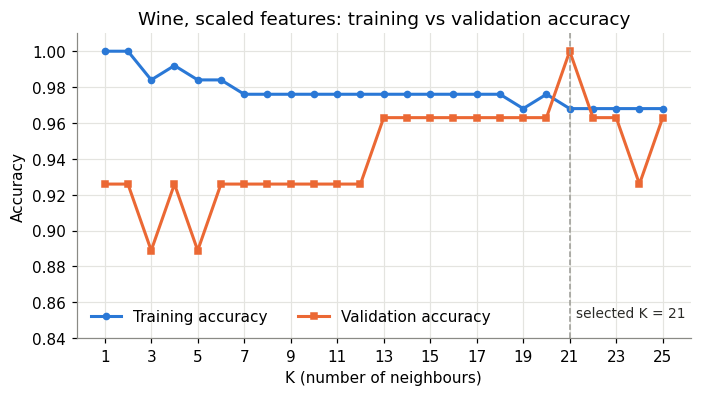

In [7]:
# =============================================================================
# Q1(b) STEP 1: sweep K = 1..25 on the SCALED data (Euclidean, uniform votes).
#
# Training accuracy = predict the training wines themselves (each wine is its
# own nearest neighbour at distance 0, so K = 1 is trivially 100 %).
#
# K-SELECTION RULE (stated): choose the K with the highest validation accuracy.
# If several K tie, take the LARGEST of them: with equal validation accuracy,
# the larger K averages over more neighbours, gives a smoother boundary and
# has lower variance.
# =============================================================================
K_RANGE = np.arange(1, 26)

def sweep(Xa, Xb, ya, yb, ks, metric='euclidean', weights='uniform'):
    """Return (train_acc, val_acc) arrays for every K in ks."""
    tr_acc, va_acc = [], []
    for k in ks:
        m = KNNScratch(k, metric, weights).fit(Xa, ya)
        tr_acc.append(accuracy(ya, m.predict(Xa)))
        va_acc.append(accuracy(yb, m.predict(Xb)))
    return np.array(tr_acc), np.array(va_acc)

def select_k(ks, scores, higher_is_better=True):
    """Best K by the score; ties -> the largest K. Returns (K, list of tied K)."""
    s = np.asarray(scores) if higher_is_better else -np.asarray(scores)
    tied = np.asarray(ks)[np.isclose(s, s.max(), rtol=0, atol=1e-12)]
    return int(tied.max()), tied.tolist()

tr_sc, va_sc = sweep(Xtr, Xva, ytr, yva, K_RANGE)
K_SEL, K_TIED = select_k(K_RANGE, va_sc)

sweep_tab = pd.DataFrame({'train acc': tr_sc.round(3), 'val acc': va_sc.round(3)}, index=pd.Index(K_RANGE, name='K'))
print(sweep_tab.T.to_string())
print(f'\nBest validation accuracy = {va_sc.max():.4f} at K = {K_TIED}  ->  selected K = {K_SEL}')
print('One validation wine =', round(1 / len(yva), 4), 'accuracy, so a 1-wine change moves the curve by that much.')

fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.plot(K_RANGE, tr_sc, '-o', color=BLUE, ms=4, lw=2, label='Training accuracy')
ax.plot(K_RANGE, va_sc, '-s', color=ORANGE, ms=4, lw=2, label='Validation accuracy')
ax.axvline(K_SEL, color=GREY, ls='--', lw=1)
ax.annotate(f'selected K = {K_SEL}', (K_SEL, 0.852), xytext=(4, 0), textcoords='offset points', color=INK, fontsize=9)
ax.set(xlabel='K (number of neighbours)', ylabel='Accuracy', xticks=K_RANGE[::2], ylim=(0.84, 1.01),
       title='Wine, scaled features: training vs validation accuracy')
ax.legend(loc='lower left', ncol=2)
savefig('q1b_scaled_curves.png'); plt.show()

RESULTS['q1_sweep_scaled'] = {'K': K_RANGE.tolist(), 'train': tr_sc.round(4).tolist(), 'val': va_sc.round(4).tolist()}
RESULTS['q1_K_sel'] = K_SEL
RESULTS['q1_K_tied'] = K_TIED

K                    1      2      3      4      5      6      7      8      9      10     11     12     13     14     15     16     17     18     19     20     21     22     23     24     25
val scaled        0.926  0.926  0.889  0.926  0.889  0.926  0.926  0.926  0.926  0.926  0.926  0.926  0.963  0.963  0.963  0.963  0.963  0.963  0.963  0.963  1.000  0.963  0.963  0.926  0.963
val unscaled      0.667  0.667  0.630  0.667  0.667  0.667  0.630  0.667  0.667  0.704  0.667  0.667  0.667  0.667  0.667  0.667  0.667  0.667  0.667  0.667  0.667  0.667  0.667  0.704  0.704
val proline only  0.704  0.704  0.667  0.667  0.630  0.667  0.593  0.704  0.667  0.704  0.704  0.704  0.667  0.704  0.704  0.704  0.667  0.667  0.667  0.667  0.667  0.667  0.667  0.667  0.667
train unscaled    1.000  1.000  0.880  0.880  0.840  0.840  0.784  0.792  0.792  0.768  0.744  0.744  0.736  0.768  0.752  0.744  0.736  0.752  0.752  0.744  0.728  0.744  0.728  0.744  0.752

Mean validation accuracy over K=1..25: 

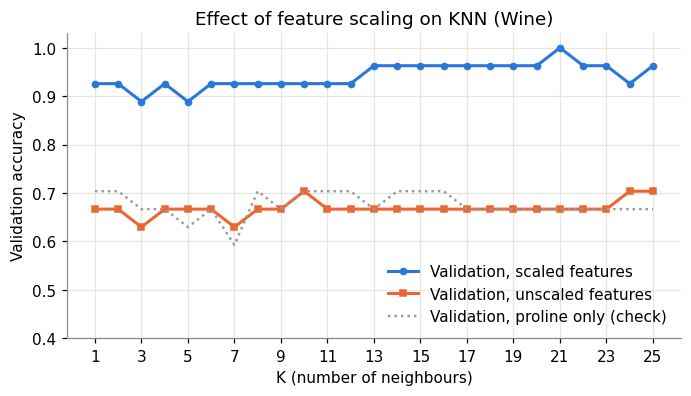


                    train std  share of squared Euclidean distance (%)  share of std, ~Manhattan (%)
proline              305.777                                   99.733                         92.09
magnesium             15.149                                    0.245                          4.56
alcalinity_of_ash      3.393                                    0.012                          1.02
color_intensity        2.383                                    0.006                          0.72
alcohol                0.806                                    0.001                          0.24

Proline by class (training wines):
         mean    min     max
class                       
0      1113.0  680.0  1515.0
1       531.0  278.0   985.0
2       625.0  415.0   880.0


In [8]:
# =============================================================================
# Q1(b) STEP 2: the same sweep on the UNSCALED (raw) features, plotted against
# the scaled validation curve. Extra check (not asked): a model that uses
# ONLY the proline column, to test whether proline alone drives the raw model.
# =============================================================================
tr_raw, va_raw = sweep(Xtr_raw, Xva_raw, ytr, yva, K_RANGE)
_, va_pro = sweep(Xtr_raw[:, [12]], Xva_raw[:, [12]], ytr, yva, K_RANGE)   # column 12 = proline

print(pd.DataFrame({'val scaled': va_sc.round(3), 'val unscaled': va_raw.round(3),
                    'val proline only': va_pro.round(3), 'train unscaled': tr_raw.round(3)},
                   index=pd.Index(K_RANGE, name='K')).T.to_string())
print(f'\nMean validation accuracy over K=1..25: scaled {va_sc.mean():.4f} | unscaled {va_raw.mean():.4f} | proline only {va_pro.mean():.4f}')

fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.plot(K_RANGE, va_sc, '-o', color=BLUE, ms=4, lw=2, label='Validation, scaled features')
ax.plot(K_RANGE, va_raw, '-s', color=ORANGE, ms=4, lw=2, label='Validation, unscaled features')
ax.plot(K_RANGE, va_pro, ':', color=GREY, lw=1.6, label='Validation, proline only (check)')
ax.set(xlabel='K (number of neighbours)', ylabel='Validation accuracy', xticks=K_RANGE[::2], ylim=(0.4, 1.03),
       title='Effect of feature scaling on KNN (Wine)')
ax.legend(loc='lower right')
savefig('q1b_scaling.png'); plt.show()

# Which features dominate the raw Euclidean distance?
# For two random wines, E[(x_j - x'_j)^2] = 2 Var(x_j), so feature j's share of
# the expected squared distance is Var_j / sum(Var). For Manhattan the share is
# roughly proportional to the spread (std) instead of the variance.
var_tr = Xtr_raw.var(axis=0); sd_tr = Xtr_raw.std(axis=0)
dom = pd.DataFrame({'train std': sd_tr.round(3),
                    'share of squared Euclidean distance (%)': (100 * var_tr / var_tr.sum()).round(3),
                    'share of std, ~Manhattan (%)': (100 * sd_tr / sd_tr.sum()).round(2)}, index=FEATURES)
dom = dom.sort_values('share of squared Euclidean distance (%)', ascending=False)
print('\n', dom.head(5).to_string())

# proline by class (training set): does proline alone separate the cultivars?
print('\nProline by class (training wines):')
print(pd.DataFrame({'proline': Xtr_raw[:, 12], 'class': ytr}).groupby('class')['proline'].agg(['mean', 'min', 'max']).round(0).to_string())

RESULTS['q1_sweep_unscaled'] = {'train': tr_raw.round(4).tolist(), 'val': va_raw.round(4).tolist(),
                                'val_proline': va_pro.round(4).tolist()}
RESULTS['q1_mean_val'] = {'scaled': round(va_sc.mean(), 4), 'unscaled': round(va_raw.mean(), 4),
                          'proline': round(va_pro.mean(), 4)}
RESULTS['q1_dominance'] = dom.head(5).reset_index().rename(columns={'index': 'feature'}).to_dict('records')

K =   1: train 1.0000 | val 0.9259
K =  25: train 0.9680 | val 0.9630
K =  50: train 0.9760 | val 0.9630
K =  75: train 0.9440 | val 0.9630
K =  90: train 0.7520 | val 0.6296
K = 100: train 0.4960 | val 0.4444
K = 110: train 0.4000 | val 0.4074
K = 125: train 0.4000 | val 0.4074
Training class counts: [41 50 34] -> majority-class share = 0.4
Lowest validation accuracy for 25 <= K <= 75: 0.9259
First K above 25 where validation accuracy falls below 0.9: 81
Share of class 1 in the validation set: 0.4074


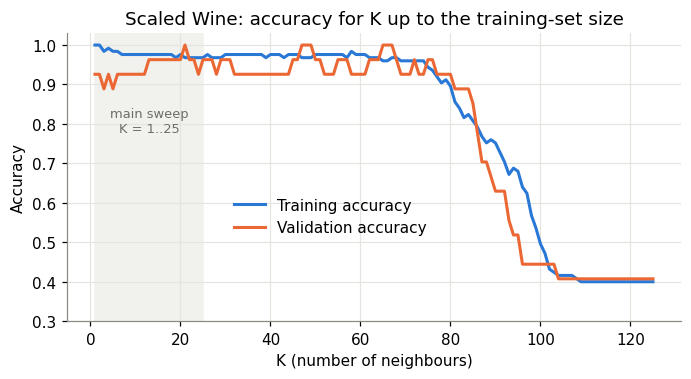

In [9]:
# =============================================================================
# Q1(b) EXTRA (beyond the sheet): continue the scaled sweep up to K = 125
# (= every training wine) so the UNDERFITTING end becomes visible. Within
# K = 1..25 the classes are so well separated that it barely shows.
# =============================================================================
K_LONG = np.arange(1, len(ytr) + 1)
tr_long, va_long = sweep(Xtr, Xva, ytr, yva, K_LONG)
for k in [1, 25, 50, 75, 90, 100, 110, 125]:
    print(f'K = {k:3d}: train {tr_long[k-1]:.4f} | val {va_long[k-1]:.4f}')
print('Training class counts:', np.bincount(ytr), '-> majority-class share =', round(np.bincount(ytr).max() / len(ytr), 4))
print('Lowest validation accuracy for 25 <= K <= 75:', round(va_long[24:75].min(), 4))
first_drop = int(K_LONG[25:][np.argmax(va_long[25:] < 0.9)])
print('First K above 25 where validation accuracy falls below 0.9:', first_drop)
print('Share of class 1 in the validation set:', round(np.mean(yva == 1), 4))

fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.axvspan(1, 25, color='#f1f1ee', zorder=0)
ax.text(13, 0.78, 'main sweep\nK = 1..25', ha='center', fontsize=8.5, color='#6d6d68')
ax.plot(K_LONG, tr_long, '-', color=BLUE, lw=2, label='Training accuracy')
ax.plot(K_LONG, va_long, '-', color=ORANGE, lw=2, label='Validation accuracy')
ax.set(xlabel='K (number of neighbours)', ylabel='Accuracy', ylim=(0.3, 1.03),
       title='Scaled Wine: accuracy for K up to the training-set size')
ax.legend(loc='lower left', bbox_to_anchor=(0.25, 0.25))
savefig('q1b_long_sweep.png'); plt.show()

RESULTS['q1_long'] = {str(k): [round(tr_long[k-1], 4), round(va_long[k-1], 4)] for k in [1, 25, 50, 75, 90, 100, 110, 125]}
RESULTS['q1_majority_share'] = round(np.bincount(ytr).max() / len(ytr), 4)
RESULTS['q1_long_min25_75'] = round(va_long[24:75].min(), 4)
RESULTS['q1_long_first_below_09'] = first_drop

**Choice of K.** Validation accuracy is highest (**1.000**, all 27 wines correct) at **K = 21** only, so K = 21 is selected and no tie rule is needed. One honest caveat: one validation wine is worth 3.7 percentage points, and K = 13–20, 22, 23 and 25 all reach 0.963 (a single error). So K = 21 is the best by the stated rule, but any K from about 13 to 25 would be almost as good.

**Why the unscaled model is worse.** Without scaling, the distance is computed in raw units, so a feature with large numbers decides almost everything. Proline (training standard deviation 306) supplies **99.7 %** of the expected squared Euclidean distance between two wines; magnesium is a distant second with 0.25 %, and the other 11 features together supply less than 0.03 %. The unscaled model is therefore close to a KNN on proline alone, and the extra check confirms this: proline-only KNN has mean validation accuracy 0.676, the unscaled model 0.668, and the scaled model 0.942. Proline separates class 0 (high proline, mean about 1100) from the other two, but classes 1 and 2 overlap heavily on proline (means about 530 and 625), so the unscaled model gets stuck around 0.63–0.70 whatever K is. Scaling gives each of the 13 measurements an equal say, and the useful ones (flavanoids, colour intensity, hue, …) start to count.

**Overfitting and underfitting.** At K = 1 and 2 the training accuracy is 1.000 because every training wine finds itself at distance 0, while validation accuracy is only 0.926: the gap is overfitting (high variance). As K grows, the training accuracy falls to about 0.97 and validation accuracy rises to 0.96–1.00, so the gap closes. Inside K = 1 … 25 there is no clear underfitting, because the three cultivars are well separated once scaled. The extra long sweep shows it: validation accuracy stays at 0.926 or above from K = 25 to K = 75, first falls below 0.9 at K = 81, and from K = 110 the training accuracy is 0.400 and the validation accuracy 0.407. These are exactly the shares of class 1, the largest class, in each set (50 of 125 and 11 of 27), so at that point every wine gets the majority label: pure underfitting (high bias). The long sweep also reaches 1.000 again at K = 47–49 and 65–67, another sign that 27 validation wines cannot rank nearby K values reliably.

### (c) Distance metric, weighting and the test evaluation

In [10]:
# =============================================================================
# Q1(c) STEP 1: at the selected K, compare Euclidean vs Manhattan distance and
# uniform vs inverse-distance-weighted voting on the validation set (2x2 table).
#
# SELECTION RULE (stated): highest validation accuracy. If combinations tie,
# prefer inverse-distance weighting, because weighted vote totals are real
# numbers that practically never tie, so the prediction does not depend on the
# arbitrary tie-breaking rule. A remaining tie goes to Euclidean (the default).
# =============================================================================
combo = {}
for metric in ['euclidean', 'manhattan']:
    for wts in ['uniform', 'distance']:
        m = KNNScratch(K_SEL, metric, wts).fit(Xtr, ytr)
        combo[(metric, wts)] = (accuracy(yva, m.predict(Xva)), m.n_ties_)

table = pd.DataFrame([[combo[(mt, w)][0] for w in ['uniform', 'distance']] for mt in ['euclidean', 'manhattan']],
                     index=['Euclidean', 'Manhattan'], columns=['Uniform voting', 'Inverse-distance voting']).round(4)
print(f'Validation accuracy at K = {K_SEL}:')
print(table.to_string())
print('\nValidation wines that needed the tie-break rule:',
      {f'{a}/{b}': v[1] for (a, b), v in combo.items()})

order = [('euclidean', 'distance'), ('euclidean', 'uniform'), ('manhattan', 'distance'), ('manhattan', 'uniform')]
best_acc = max(v[0] for v in combo.values())
BEST_METRIC, BEST_WTS = next(c for c in order if np.isclose(combo[c][0], best_acc))
print(f'\nBest combination: {BEST_METRIC} distance with {BEST_WTS} voting (validation accuracy {best_acc:.4f})')

RESULTS['q1_table'] = table.reset_index().rename(columns={'index': 'metric'}).to_dict('records')
RESULTS['q1_ties_table'] = {f'{a}/{b}': v[1] for (a, b), v in combo.items()}
RESULTS['q1_best'] = [BEST_METRIC, BEST_WTS]

Validation accuracy at K = 21:
           Uniform voting  Inverse-distance voting
Euclidean           1.000                    1.000
Manhattan           0.963                    0.963

Validation wines that needed the tie-break rule: {'euclidean/uniform': 1, 'euclidean/distance': 0, 'manhattan/uniform': 1, 'manhattan/distance': 0}

Best combination: euclidean distance with distance voting (validation accuracy 1.0000)


Test accuracy: 1.0000  (26 of 26 wines correct)

Confusion matrix (rows = true class, columns = predicted class):
        pred 0  pred 1  pred 2
true 0       9       0       0
true 1       0      10       0
true 2       0       0       7

          precision  recall  support
class 0        1.0     1.0        9
class 1        1.0     1.0       10
class 2        1.0     1.0        7

With 26 test wines and 0 errors, the 95% lower bound on true accuracy is 0.868


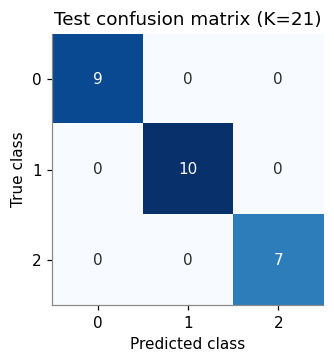

In [11]:
# =============================================================================
# Q1(c) STEP 2: ONE evaluation on the untouched test set with the best
# combination. Confusion matrix, precision and recall are computed by hand:
#   confusion[i, j] = number of wines of true class i predicted as class j
#   precision_c = TP_c / (all predicted as c)  = C[c,c] / column sum
#   recall_c    = TP_c / (all truly c)         = C[c,c] / row sum
# =============================================================================
final = KNNScratch(K_SEL, BEST_METRIC, BEST_WTS).fit(Xtr, ytr)
p_test = final.predict(Xte)
test_acc = accuracy(yte, p_test)

n_cls = len(np.unique(y_wine))
conf = np.zeros((n_cls, n_cls), dtype=int)
np.add.at(conf, (yte, p_test), 1)                     # count (true, predicted) pairs

tp = np.diag(conf)
precision = tp / np.maximum(conf.sum(axis=0), 1)      # guard against an empty column
recall = tp / np.maximum(conf.sum(axis=1), 1)

print(f'Test accuracy: {test_acc:.4f}  ({int((p_test == yte).sum())} of {len(yte)} wines correct)')
print('\nConfusion matrix (rows = true class, columns = predicted class):')
print(pd.DataFrame(conf, index=[f'true {c}' for c in range(n_cls)], columns=[f'pred {c}' for c in range(n_cls)]).to_string())
prf = pd.DataFrame({'precision': precision.round(4), 'recall': recall.round(4), 'support': conf.sum(axis=1)},
                   index=[f'class {c}' for c in range(n_cls)])
print('\n', prf.to_string())

# 95 % lower confidence bound for accuracy when all n test wines are correct
# (exact binomial / Clopper-Pearson): p_low = (alpha/2)^(1/n)
n_te = len(yte)
if test_acc == 1.0:
    print(f'\nWith {n_te} test wines and 0 errors, the 95% lower bound on true accuracy is {(0.025) ** (1 / n_te):.3f}')

fig, ax = plt.subplots(figsize=(3.6, 3.2))
ax.imshow(conf, cmap='Blues', vmin=0)
for i in range(n_cls):
    for j in range(n_cls):
        ax.text(j, i, conf[i, j], ha='center', va='center', color='white' if conf[i, j] > conf.max() / 2 else INK)
ax.set(xticks=range(n_cls), yticks=range(n_cls), xlabel='Predicted class', ylabel='True class',
       title=f'Test confusion matrix (K={K_SEL})')
ax.grid(False)
savefig('q1c_confusion.png'); plt.show()

RESULTS['q1_test_acc'] = round(test_acc, 4)
RESULTS['q1_conf'] = conf.tolist()
RESULTS['q1_prec'] = precision.round(4).tolist()
RESULTS['q1_rec'] = recall.round(4).tolist()
RESULTS['q1_test_lower95'] = round(0.025 ** (1 / n_te), 3) if test_acc == 1.0 else None

In [12]:
# =============================================================================
# Q1(c) STEP 3: prediction time on the test set, ours vs sklearn.
# Each predict() call is repeated 300 times and the MEDIAN is reported, because
# a single call of well under a millisecond is dominated by timer noise.
# sklearn's default algorithm='auto' picks a KD-tree here; 'brute' (the same
# idea as ours: all pairwise distances) is timed too for a like-for-like view.
# Exact times depend on the machine, so they will differ slightly on Colab.
# =============================================================================
def median_ms(fn, reps=300):
    """Median wall-clock time of fn() in milliseconds."""
    for _ in range(10):                      # warm-up calls (caches, lazy imports)
        fn()
    t = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); t.append(time.perf_counter() - t0)
    return 1e3 * float(np.median(t))

sk_auto = KNeighborsClassifier(K_SEL, metric=BEST_METRIC, weights=BEST_WTS).fit(Xtr, ytr)
sk_brute = KNeighborsClassifier(K_SEL, metric=BEST_METRIC, weights=BEST_WTS, algorithm='brute').fit(Xtr, ytr)
assert np.array_equal(sk_auto.predict(Xte), p_test)  # same predictions as ours

t_ours = median_ms(lambda: final.predict(Xte))
t_auto = median_ms(lambda: sk_auto.predict(Xte))
t_brute = median_ms(lambda: sk_brute.predict(Xte))
timing = pd.DataFrame({'median predict time (ms)': [t_ours, t_auto, t_brute]},
                      index=['ours (NumPy, vectorised)', f'sklearn auto ({sk_auto._fit_method})', 'sklearn brute']).round(3)
print(f'Predicting {len(yte)} test wines against {len(ytr)} training wines:')
print(timing.to_string())

RESULTS['q1_timing'] = {'ours': round(t_ours, 3), 'sk_auto': round(t_auto, 3), 'sk_brute': round(t_brute, 3),
                        'sk_auto_method': sk_auto._fit_method}

Predicting 26 test wines against 125 training wines:
                          median predict time (ms)
ours (NumPy, vectorised)                     0.150
sklearn auto (kd_tree)                       0.353
sklearn brute                                5.893


**Metric and weighting.** At K = 21, Euclidean distance (1.000) beats Manhattan (0.963) by one validation wine; inverse-distance weighting gives the same accuracy as uniform voting for both metrics. Euclidean-uniform and Euclidean-weighted tie, so by the stated rule we use **Euclidean + inverse-distance weighting**. The reason is visible in the output: with uniform voting one validation wine had a vote tie and needed the tie-break rule, while weighted votes never tied.

**Test result.** The single test evaluation classifies **all 26 test wines correctly** (accuracy 1.000), so the confusion matrix is diagonal and precision and recall are 1.000 for every class. This should not be read as "KNN is perfect on wine": with only 26 test wines and no errors, the 95 % lower bound on the true accuracy is still only 0.868.

**Speed.** Both implementations do the same work (all distances from 26 test wines to 125 training wines), so the times in the table reflect overhead. In our run, our vectorised NumPy version was faster than sklearn's: on a problem this small, sklearn's fixed costs (input checks, the KD-tree search that `auto` chose) take longer than the arithmetic itself. The exact times depend on the machine and will differ slightly on Colab.

### (d) Interpretation and analysis
The plot below is an extra illustration (two features only, so the boundary can be drawn). The answer to (d) follows it.

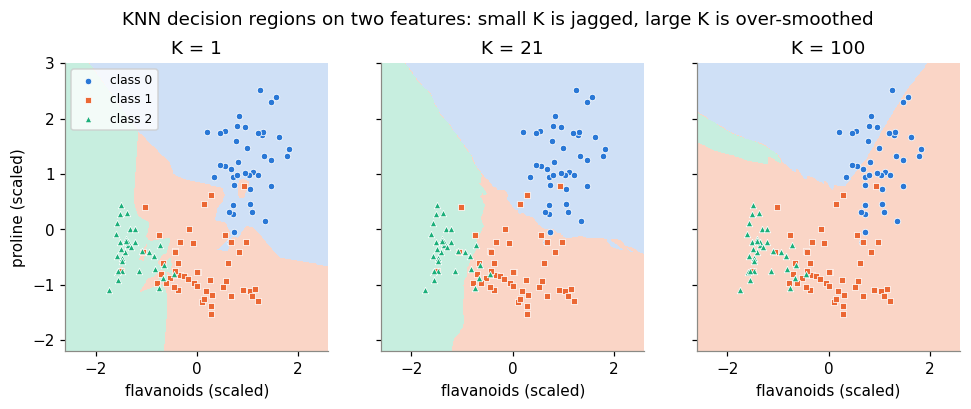

In [13]:
# =============================================================================
# Q1(d) EXTRA ILLUSTRATION (beyond the sheet): decision regions of our KNN on
# just TWO scaled features (flavanoids, proline) for a very small, the
# selected and a very large K. Two features are used only so the boundary can
# be drawn; the main model above uses all 13.
# =============================================================================
f1, f2 = FEATURES.index('flavanoids'), FEATURES.index('proline')
X2 = Xtr[:, [f1, f2]]
g1, g2 = np.meshgrid(np.linspace(-2.6, 2.6, 260), np.linspace(-2.2, 3.0, 260))
grid = np.c_[g1.ravel(), g2.ravel()]                     # 67,600 query points, predicted in one call

from matplotlib.colors import ListedColormap
region_cmap = ListedColormap(['#cfe0f6', '#fad5c6', '#c7eedf'])
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4), sharey=True)
for ax, k in zip(axes, [1, K_SEL, 100]):
    zz = KNNScratch(k).fit(X2, ytr).predict(grid).reshape(g1.shape)
    ax.contourf(g1, g2, zz, levels=[-0.5, 0.5, 1.5, 2.5], cmap=region_cmap)
    for c in range(3):
        ax.scatter(*X2[ytr == c].T, s=18, c=CLASS_COL[c], marker=CLASS_MRK[c], edgecolor='white', lw=0.5, label=f'class {c}')
    ax.set(title=f'K = {k}', xlabel='flavanoids (scaled)')
    ax.grid(False)
axes[0].set_ylabel('proline (scaled)')
axes[0].legend(loc='upper left', fontsize=8, frameon=True)
fig.suptitle('KNN decision regions on two features: small K is jagged, large K is over-smoothed', y=1.02)
savefig('q1d_boundaries.png'); plt.show()

**Answer (d).** With very small K (K = 1) the decision boundary follows individual training wines, so it is jagged and wraps around single unusual points: bias is low but variance is high, which is why training accuracy is 100 % while validation accuracy is lower and jumps around. As K grows, each prediction averages over more neighbours, so the boundary becomes smoother and variance falls while bias rises; at very large K the largest class takes over (in the long sweep every wine is called class 1 from K = 110), which is maximum bias. KNN has no training phase because "fitting" only stores the training data, so all the work is pushed to prediction time. To classify one wine it must compute the distance to every stored training wine and pick the closest K, so each prediction costs time proportional to (number of training points × number of features), and the whole training set must be kept in memory. One practical limitation on this data set is that KNN gives every feature the same weight in the distance, so it is only usable after scaling: on the raw measurements proline alone decides the neighbours and validation accuracy drops from about 0.94 to about 0.67.

---
## Question 2 — KNN on synthetic data with a known ground truth

### (a) KNN regression and the choice of K

In [14]:
# =============================================================================
# Q2(a) STEP 1: synthetic regression data y = sin(2*pi*x) + noise.
#   x ~ Uniform(0, 1), noise ~ N(0, 0.3^2)  ->  noise variance sigma^2 = 0.09
# Split 60:20:20 with a seeded random permutation, then fit sklearn's
# KNeighborsRegressor for each K. The prediction is the MEAN y of the K
# nearest training x values.
# K selection: lowest validation MSE (ties -> larger K, as in Q1).
# =============================================================================
np.random.seed(42)
N = 300
x_all = np.random.uniform(0, 1, N)
noise = np.random.normal(0, 0.3, N)
f_true = lambda x: np.sin(2 * np.pi * x)
y_all = f_true(x_all) + noise

perm = np.random.permutation(N)
n_tr, n_va = int(0.6 * N), int(0.2 * N)
i_tr, i_va, i_te = perm[:n_tr], perm[n_tr:n_tr + n_va], perm[n_tr + n_va:]
xr_tr, xr_va, xr_te = x_all[i_tr, None], x_all[i_va, None], x_all[i_te, None]
yr_tr, yr_va, yr_te = y_all[i_tr], y_all[i_va], y_all[i_te]
print('Sizes: train', len(i_tr), '| val', len(i_va), '| test', len(i_te))

mse = lambda a, b: float(np.mean((np.asarray(a) - np.asarray(b)) ** 2))
K_REG = [1, 3, 5, 10, 20, 50, 100, len(i_tr)]          # last one = training-set size
rows = []
for k in K_REG:
    reg = KNeighborsRegressor(n_neighbors=k).fit(xr_tr, yr_tr)
    rows.append({'K': k, 'train MSE': mse(yr_tr, reg.predict(xr_tr)), 'val MSE': mse(yr_va, reg.predict(xr_va))})
reg_tab = pd.DataFrame(rows)
print(reg_tab.round(4).to_string(index=False))

K_REG_SEL, _ = select_k(reg_tab['K'], reg_tab['val MSE'], higher_is_better=False)
best_reg = KNeighborsRegressor(n_neighbors=K_REG_SEL).fit(xr_tr, yr_tr)
test_mse = mse(yr_te, best_reg.predict(xr_te))

# What would a PERFECT model (the true function itself) score on these sets?
oracle = {s: mse(y_all[i], f_true(x_all[i])) for s, i in [('train', i_tr), ('val', i_va), ('test', i_te)]}
print(f'\nSelected K = {K_REG_SEL} (lowest validation MSE)')
print(f'Test MSE at K = {K_REG_SEL}: {test_mse:.4f}')
print(f'Noise variance sigma^2 = {0.3**2:.4f}')
print('MSE of the TRUE function sin(2*pi*x) on each set (= that set\'s own noise):',
      {k: round(v, 4) for k, v in oracle.items()})
print(f'Excess test MSE over the true function: {test_mse - oracle["test"]:.4f}')
print(f'Variance of training y (what predicting a constant costs): {yr_tr.var():.4f}')

RESULTS['q2a_table'] = reg_tab.round(4).to_dict('records')
RESULTS['q2a_K_sel'] = K_REG_SEL
RESULTS['q2a_test_mse'] = round(test_mse, 4)
RESULTS['q2a_oracle'] = {k: round(v, 4) for k, v in oracle.items()}
RESULTS['q2a_var_ytr'] = round(float(yr_tr.var()), 4)

Sizes: train 180 | val 60 | test 60
  K  train MSE  val MSE
  1     0.0000   0.1384
  3     0.0675   0.0842
  5     0.0783   0.0660
 10     0.0876   0.0590
 20     0.0954   0.0588
 50     0.1371   0.1112
100     0.1873   0.1571
180     0.5919   0.5187

Selected K = 20 (lowest validation MSE)
Test MSE at K = 20: 0.1182
Noise variance sigma^2 = 0.0900
MSE of the TRUE function sin(2*pi*x) on each set (= that set's own noise): {'train': 0.0932, 'val': 0.0543, 'test': 0.1061}
Excess test MSE over the true function: 0.0121
Variance of training y (what predicting a constant costs): 0.5919


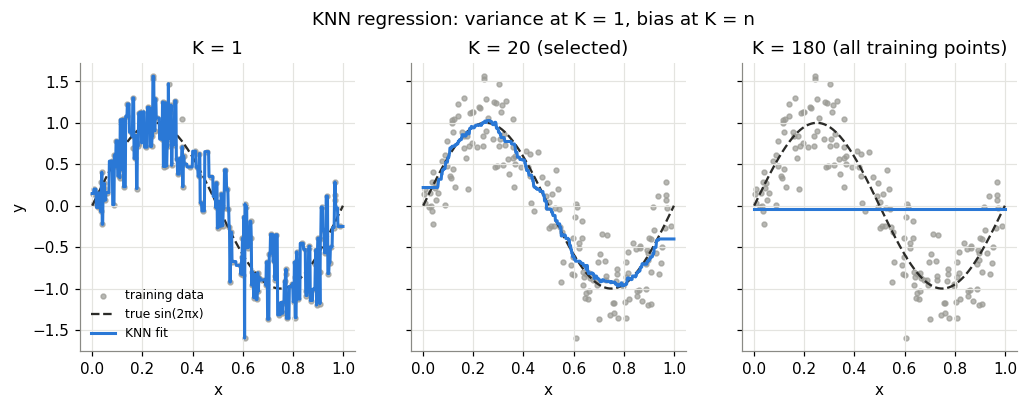

In [15]:
# =============================================================================
# Q2(a) STEP 2: fitted curves for K = 1, the selected K and K = n_train, drawn
# over the training data and the true function.
# =============================================================================
xs = np.linspace(0, 1, 600)[:, None]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, k, tag in zip(axes, [1, K_REG_SEL, len(i_tr)], ['K = 1', f'K = {K_REG_SEL} (selected)', f'K = {len(i_tr)} (all training points)']):
    reg = KNeighborsRegressor(n_neighbors=k).fit(xr_tr, yr_tr)
    ax.scatter(xr_tr, yr_tr, s=10, color=GREY, alpha=0.7, label='training data')
    ax.plot(xs, f_true(xs), '--', color=INK, lw=1.5, label='true sin(2πx)')
    ax.plot(xs, reg.predict(xs), color=BLUE, lw=2, label='KNN fit')
    ax.set(title=tag, xlabel='x')
axes[0].set_ylabel('y')
axes[0].legend(loc='lower left', fontsize=8)
fig.suptitle('KNN regression: variance at K = 1, bias at K = n', y=1.02)
savefig('q2a_fits.png'); plt.show()

**Choice of K.** The lowest validation MSE is at **K = 20** (0.0588), only just ahead of K = 10 (0.0590); both are good choices. The test MSE at K = 20 is **0.1182**.

**The two extremes.**

* **K = 1** (low bias, high variance): the fit passes through every training point (training MSE 0), so it copies the noise. The curve is a jagged staircase and the validation MSE is 0.138.
* **K = 180** (all training points; high bias, low variance): every prediction is the mean of all 180 training y values, a flat line near 0. It ignores x completely, so it cannot follow the sine wave; validation MSE is 0.519, close to the variance of y itself (0.592 on the training set).
* In between, K = 10–20 averages enough neighbours to cancel much of the noise while staying local enough to follow the curve.

**Best achievable test MSE vs noise.** The noise has variance σ² = 0.3² = 0.09. No model can predict the noise, so on average no model can get a test MSE below 0.09. This is the irreducible error. On these 60 particular test points, even the true function sin(2πx) scores 0.106 (the test noise happened to be a little larger than 0.09), and KNN with K = 20 scores 0.118, only about 0.012 above that floor. The same effect explains why the validation MSE (0.059) is below 0.09: the 60 validation points happen to have small noise (the true function scores 0.054 on them).

### (b) Distance concentration

   d  median ratio  median d_min  median d_max  mean distance  sqrt(d/6)
   1     1855.3244        0.0004        0.7671         0.3400     0.4082
   2       83.9397        0.0136        1.0924         0.5387     0.5774
   5        7.1744        0.1799        1.4611         0.8690     0.9129
  10        2.9247        0.4952        1.8944         1.2521     1.2910
  20        1.3732        1.0249        2.4538         1.8095     1.8257
  50        0.6664        2.1258        3.5516         2.8770     2.8868
 100        0.4312        3.3278        4.7697         4.0813     4.0825
 500        0.1716        8.4204        9.8464         9.1363     9.1287
1000        0.1187       12.1865       13.6201        12.8941    12.9099

(The mean distance between two uniform points is about sqrt(d/6) for large d.)


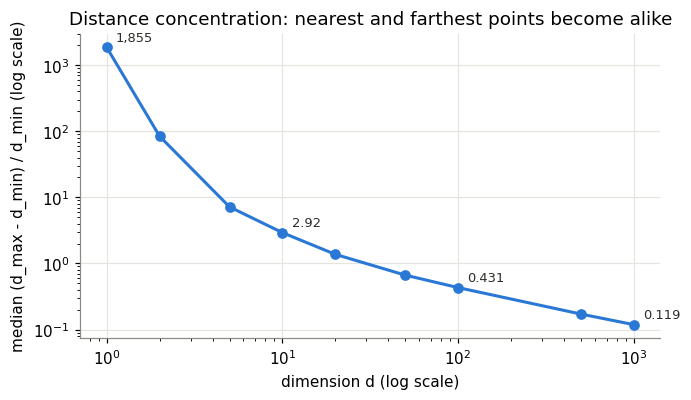

In [16]:
# =============================================================================
# Q2(b): DISTANCE CONCENTRATION in high dimensions.
# For each d: 1000 points uniform in [0,1]^d; the first 100 are queries. For
# each query we compute the Euclidean distance to the other 999 points and
# the relative contrast (d_max - d_min) / d_min; we report the median over
# the 100 queries. Distances use the matrix-product formula (no loops).
# =============================================================================
np.random.seed(42)
DIMS = [1, 2, 5, 10, 20, 50, 100, 500, 1000]
conc = []
for d in DIMS:
    P = np.random.uniform(0, 1, (1000, d))
    Q = P[:100]
    D = np.sqrt(np.maximum((Q ** 2).sum(1)[:, None] + (P ** 2).sum(1)[None, :] - 2 * Q @ P.T, 0))
    D[np.arange(100), np.arange(100)] = np.nan                  # drop the distance of a query to itself
    dmin, dmax = np.nanmin(D, axis=1), np.nanmax(D, axis=1)
    ratio = (dmax - dmin) / dmin
    conc.append({'d': d, 'median ratio': np.median(ratio), 'median d_min': np.median(dmin),
                 'median d_max': np.median(dmax), 'mean distance': np.nanmean(D),
                 'sqrt(d/6)': np.sqrt(d / 6)})
conc = pd.DataFrame(conc)
print(conc.round(4).to_string(index=False))
print('\n(The mean distance between two uniform points is about sqrt(d/6) for large d.)')

fig, ax = plt.subplots(figsize=(6.8, 3.6))
ax.plot(conc['d'], conc['median ratio'], '-o', color=BLUE, lw=2, ms=6)
for d, r in zip(conc['d'], conc['median ratio']):
    if d in (1, 10, 100, 1000):
        ax.annotate(f'{r:,.0f}' if r >= 100 else f'{r:.3g}', (d, r), xytext=(6, 4), textcoords='offset points', fontsize=8.5, color=INK)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set(xlabel='dimension d (log scale)', ylabel='median (d_max - d_min) / d_min (log scale)',
       title='Distance concentration: nearest and farthest points become alike')
savefig('q2b_concentration.png'); plt.show()

RESULTS['q2b'] = conc.round(4).to_dict('records')

**What the plot shows.** The median ratio (d_max − d_min) / d_min falls from about **1855 at d = 1** to **2.9 at d = 10**, **0.43 at d = 100** and **0.12 at d = 1000**. At d = 1000 the nearest point is at distance about 12.2 and the farthest at about 13.6.

**Why.** A squared distance is a sum of d independent squared differences. As d grows this sum gets close to its average, so every distance is close to √(d/6) (12.9 at d = 1000, matching the table), while the spread of distances stays roughly the same size. So the relative gap between the nearest and the farthest point shrinks, roughly like 1/√d.

**What it means for KNN.** In high dimensions the "nearest" neighbour is only slightly closer than a random point. Small noise can change which point is nearest, and being nearest no longer means being much more similar. KNN relies entirely on this meaning, so it weakens as the dimension grows.

### (c) Effect of irrelevant features
Note on the order of steps: we split first and then standardise with training statistics only (scaling before the split would leak test-set means and standard deviations into training).

Split sizes: 900 300 300
 m (noise features)  K all  test acc KNN all  K informative  test acc KNN 2 informative  test acc LogReg all
                  0     30            0.9833             30                      0.9833               0.9800
                  2      8            0.9700              7                      0.9833               0.9733
                  5     30            0.9633             13                      0.9800               0.9733
                 10     26            0.9633             19                      0.9833               0.9733
                 20     20            0.9300             15                      0.9800               0.9533
                 50     26            0.8533             23                      0.9833               0.9733
                100     26            0.7867              7                      0.9767               0.9500


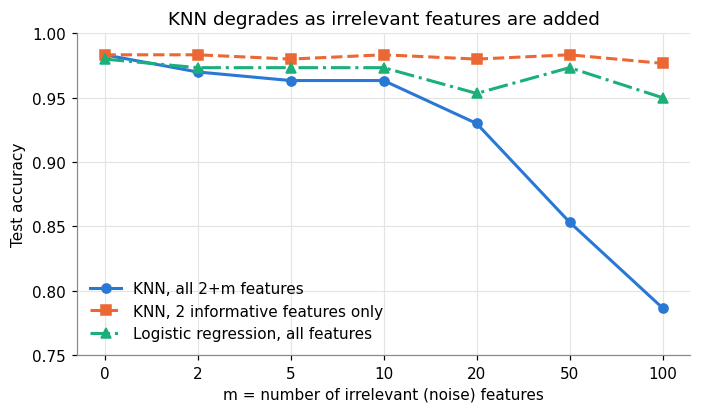

In [17]:
# =============================================================================
# Q2(c): effect of IRRELEVANT features.
# For each m: 2 informative columns + m pure-noise columns (shuffle=False keeps
# the informative ones first). Then:
#   1. split 60:20:20 with our stratified split from Q1 (seed 42). NOTE:
#      make_classification with shuffle=False returns the rows SORTED by class,
#      so a shuffled split is essential;
#   2. standardise with TRAINING mean/std only (fitting the scaler before the
#      split would leak test statistics, so we split first);
#   3. choose K in 1..30 on the validation set (ties -> largest K), separately
#      for "all features" and "2 informative columns only";
#   4. report TEST accuracy of both KNNs and of LogisticRegression (defaults,
#      all features).
# =============================================================================
M_LIST = [0, 2, 5, 10, 20, 50, 100]
K_CLS = np.arange(1, 31)

def knn_select_and_test(Xa, ya, Xb, yb, Xc, yc):
    """Pick K on (Xb, yb) by accuracy, return (K, val acc, test acc)."""
    va = [accuracy(yb, KNeighborsClassifier(k).fit(Xa, ya).predict(Xb)) for k in K_CLS]
    k_best, _ = select_k(K_CLS, va)
    te = accuracy(yc, KNeighborsClassifier(k_best).fit(Xa, ya).predict(Xc))
    return k_best, max(va), te

rows = []
for m in M_LIST:
    Xm, ym = make_classification(n_samples=1500, n_features=2 + m, n_informative=2, n_redundant=0,
                                 n_repeated=0, n_clusters_per_class=1, class_sep=1.5,
                                 shuffle=False, random_state=42)
    a, b, c = stratified_split(ym, (0.6, 0.2, 0.2), seed=42)
    mu, sd = Xm[a].mean(axis=0), Xm[a].std(axis=0)
    Za, Zb, Zc = (Xm[a] - mu) / sd, (Xm[b] - mu) / sd, (Xm[c] - mu) / sd

    k_all, v_all, t_all = knn_select_and_test(Za, ym[a], Zb, ym[b], Zc, ym[c])
    k_inf, v_inf, t_inf = knn_select_and_test(Za[:, :2], ym[a], Zb[:, :2], ym[b], Zc[:, :2], ym[c])
    lr = LogisticRegression(max_iter=1000).fit(Za, ym[a])
    rows.append({'m (noise features)': m, 'K all': k_all, 'test acc KNN all': t_all,
                 'K informative': k_inf, 'test acc KNN 2 informative': t_inf,
                 'test acc LogReg all': accuracy(ym[c], lr.predict(Zc))})
irr = pd.DataFrame(rows)
print('Split sizes:', len(a), len(b), len(c))
print(irr.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.2, 3.8))
pos = np.arange(len(M_LIST))                       # equally spaced positions, labelled by m
ax.plot(pos, irr['test acc KNN all'], '-o', color=BLUE, lw=2, ms=6, label='KNN, all 2+m features')
ax.plot(pos, irr['test acc KNN 2 informative'], '--s', color=ORANGE, lw=2, ms=6, label='KNN, 2 informative features only')
ax.plot(pos, irr['test acc LogReg all'], '-.^', color=AQUA, lw=2, ms=7, label='Logistic regression, all features')
ax.set(xticks=pos, xticklabels=M_LIST, xlabel='m = number of irrelevant (noise) features', ylabel='Test accuracy',
       ylim=(0.75, 1.0), title='KNN degrades as irrelevant features are added')
ax.legend(loc='lower left')
savefig('q2c_irrelevant.png'); plt.show()

RESULTS['q2c'] = irr.round(4).to_dict('records')

**What the plot shows.**

* **KNN on all features** falls steadily as noise columns are added: test accuracy **0.983 (m = 0) → 0.963 (m = 10) → 0.930 (m = 20) → 0.853 (m = 50) → 0.787 (m = 100)**.
* **KNN on the 2 informative columns only** stays between 0.977 and 0.983 for every m. The two informative columns are the same numbers for every m. The small differences come from `make_classification`'s default `flip_y = 0.01`: about 1 % of labels are assigned at random, and which ones depends on m. This label noise also explains why no model goes much above 0.98.
* **Logistic regression on all features** moves only from 0.980 to 0.950.

So the loss comes from the noise features, not from the classification problem becoming harder.

### (d) Interpretation and analysis
**Answer (d).** Part (b) shows that as more dimensions are added, all distances become almost equal, and in (c) each noise column adds random spread to every distance that has nothing to do with the class, so the two informative columns get drowned out and the "nearest" neighbours become close to random points: KNN on all features falls from 0.983 to 0.787, while KNN on the two informative columns stays near 0.98. Logistic regression is far less affected (0.980 to 0.950) because it learns a separate weight for each feature and can push the weights of the noise columns close to zero, whereas KNN's distance gives every column the same say and has no way to learn which ones matter; changing K cannot fix this, since, as (a) showed, K only controls how much the model smooths (bias versus variance), not which features count. Two practical remedies are feature selection (keep only useful columns, e.g. chosen by mutual information or an L1-penalised model) and learning feature weights or a distance metric (e.g. Neighbourhood Components Analysis). In Question 1 the problem was different: all 13 features carried class information but on very different scales, so standardisation fixed it, whereas here every column already has the same scale and standardisation actually gives each pure-noise column as much influence as an informative one. A limitation that appears only when the training set becomes very large is prediction cost: every query must be compared with all n stored points, so prediction time and memory grow in proportion to n, and the tree indexes that speed this up lose their advantage in high dimensions.

---
## Conclusions

* **Q1:** On the scaled Wine data, our NumPy KNN matches sklearn exactly, K = 21 with Euclidean distance and inverse-distance voting is selected on the validation set, and it classifies all 26 test wines correctly. Without scaling, proline dominates the distance and accuracy falls to about 0.67.
* **Q2:** K controls the bias–variance trade-off in KNN regression (K = 20 gives a test MSE of 0.118, close to the noise floor). In high dimensions distances concentrate, and irrelevant features steadily ruin KNN while logistic regression is barely affected.

In [18]:
# =============================================================================
# Save every reported number so the PDF report can be built from the same run.
# =============================================================================
def to_py(o):
    """Convert NumPy scalars so json can write them."""
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    raise TypeError(type(o))

with open('lab8_results.json', 'w') as fh:
    json.dump(RESULTS, fh, indent=1, default=to_py)
print('Saved', len(RESULTS), 'result groups to lab8_results.json and figures to', FIG_DIR + '/')

Saved 32 result groups to lab8_results.json and figures to lab8_figures/
